# DBSCAN Clustering – Assignment Notebook
Each task is given as a question cell followed directly by its answer cells.

**File created alongside this notebook:** `mall_customers_dbscan_dataset.csv` (203 customers, same columns as the Kaggle *Mall Customers* dataset: CustomerID, Gender, Age, Annual Income (k$), Spending Score (1-100); it is synthetic, with a few deliberate outliers)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons

**1.**  
Load the 'Mall Customers' dataset (or any small customer dataset) and apply the DBSCAN algorithm using scikit-learn to cluster users based on their annual income and spending score. Print the number of clusters found and the number of noise points detected.

In [3]:
mall = pd.read_csv("mall_customers_dbscan_dataset.csv")
print("Shape:", mall.shape)
display(mall.head())

features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = StandardScaler().fit_transform(mall[features])     # scale so both features count equally

db = DBSCAN(eps=0.3, min_samples=5).fit(X)
labels = db.labels_                                    # -1 means noise

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())
print("Number of clusters found :", n_clusters)
print("Number of noise points   :", n_noise)

Shape: (203, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,27,32,80
1,2,Female,31,54,55
2,3,Male,18,79,79
3,4,Female,28,25,26
4,5,Male,49,23,84


Number of clusters found : 5
Number of noise points   : 8


**2.**  
Visualize the DBSCAN clustering results from your previous task using matplotlib — plot each cluster in a different color, and mark noise points in black. Add axis labels and a legend for clarity.

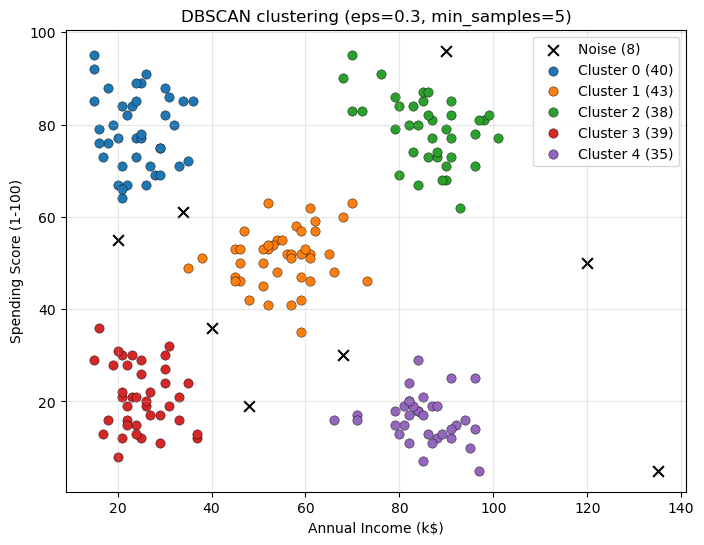

In [4]:
plt.figure(figsize=(8, 6))
cmap = plt.get_cmap("tab10")
for lab in sorted(set(labels)):
    mask = labels == lab
    if lab == -1:
        plt.scatter(mall.loc[mask, features[0]], mall.loc[mask, features[1]],
                    c="black", marker="x", s=60, label=f"Noise ({mask.sum()})")
    else:
        plt.scatter(mall.loc[mask, features[0]], mall.loc[mask, features[1]],
                    color=cmap(lab), s=45, edgecolor="k", linewidth=.3, label=f"Cluster {lab} ({mask.sum()})")
plt.xlabel("Annual Income (k$)"); plt.ylabel("Spending Score (1-100)")
plt.title("DBSCAN clustering (eps=0.3, min_samples=5)")
plt.legend(); plt.grid(alpha=.3); plt.show()

**3.**  
Change the DBSCAN parameters (eps and min_samples) to see how the number of clusters and noise points change. Write a short summary (3-4 lines) explaining how parameter choices affect the clustering outcome for your dataset.

*Hint: Try at least two different values for eps and min_samples, and compare results.*

In [5]:
results = []
for eps in (0.2, 0.3, 0.4, 0.5):
    for ms in (3, 5, 8):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        results.append({"eps": eps, "min_samples": ms,
                        "clusters": len(set(lab)) - (1 if -1 in lab else 0),
                        "noise_points": int((lab == -1).sum())})
res = pd.DataFrame(results)
display(res)
display(res.pivot(index="eps", columns="min_samples", values="clusters").rename_axis("clusters").style)
display(res.pivot(index="eps", columns="min_samples", values="noise_points").rename_axis("noise").style)

,eps,min_samples,clusters,noise_points
0,0.2,3,6,24
1,0.2,5,5,35
2,0.2,8,5,73
3,0.3,3,5,8
4,0.3,5,5,8
5,0.3,8,5,15
6,0.4,3,3,3
7,0.4,5,4,3
8,0.4,8,5,4
9,0.5,3,1,2


min_samples,3,5,8
clusters,,,
0.200000,6,5,5
0.300000,5,5,5
0.400000,3,4,5
0.500000,1,2,2


min_samples,3,5,8
noise,,,
0.200000,24,35,73
0.300000,8,8,15
0.400000,3,3,4
0.500000,2,2,2


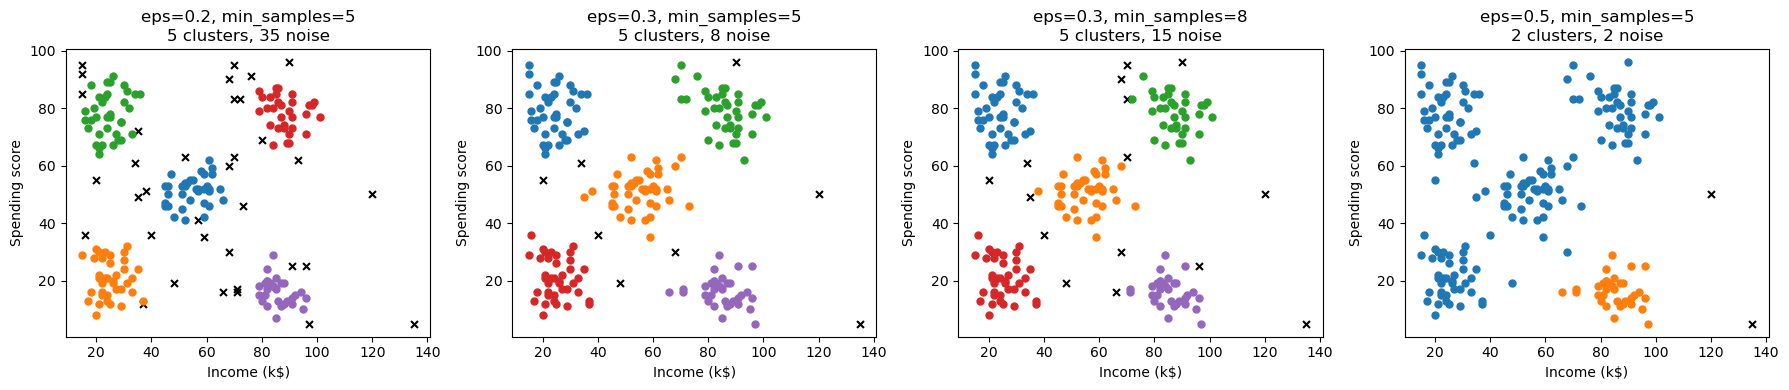

In [6]:
# Visual comparison of four settings
settings = [(0.2, 5), (0.3, 5), (0.3, 8), (0.5, 5)]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (eps, ms) in zip(axes, settings):
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
    for l in sorted(set(lab)):
        m = lab == l
        ax.scatter(mall.loc[m, features[0]], mall.loc[m, features[1]],
                   c="black" if l == -1 else [cmap(l % 10)], marker="x" if l == -1 else "o", s=25)
    ax.set_title(f"eps={eps}, min_samples={ms}\n{len(set(lab)) - (1 if -1 in lab else 0)} clusters, {(lab == -1).sum()} noise")
    ax.set_xlabel("Income (k$)"); ax.set_ylabel("Spending score")
plt.tight_layout(); plt.show()

**Summary**
- **Small eps (0.2)** makes the neighbourhood too tight: many points fail to find enough neighbours, so noise jumps (35 points with min_samples=5) and clusters can fragment (6 clusters with min_samples=3).
- **Large eps (0.5)** makes neighbourhoods overlap, so separate customer groups merge into only 1–2 big clusters and almost nothing is flagged as noise.
- **Larger min_samples** demands denser areas: at eps=0.3, moving from 5 to 8 raises noise from 8 to 15 points, because edge points of each group no longer qualify.
- For this dataset, **eps ≈ 0.3 with min_samples = 5** gives the best balance: the 5 expected customer segments plus a handful of true outliers.

**4.**  
Compare DBSCAN and K-Means on the same dataset: run both algorithms, plot their cluster assignments side by side, and briefly note which method better handles outliers or oddly-shaped clusters.

*Constraint: Use the same features and number of clusters (for K-Means) as you observed with DBSCAN.*

c:\Users\Harish\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


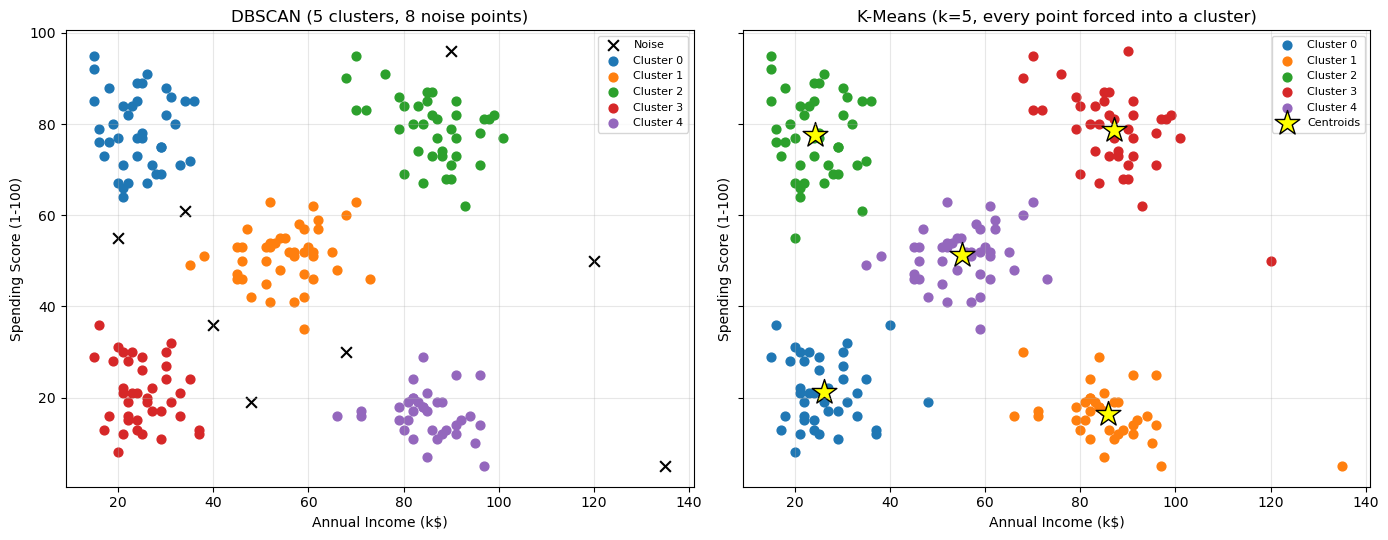

In [7]:
k = n_clusters                                          # same number of clusters DBSCAN found (5)
km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
km_labels = km.labels_

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)

# DBSCAN
for l in sorted(set(labels)):
    m = labels == l
    axes[0].scatter(mall.loc[m, features[0]], mall.loc[m, features[1]],
                    c="black" if l == -1 else [cmap(l)], marker="x" if l == -1 else "o",
                    s=60 if l == -1 else 40, label="Noise" if l == -1 else f"Cluster {l}")
axes[0].set_title(f"DBSCAN ({n_clusters} clusters, {n_noise} noise points)")

# K-Means
for l in range(k):
    m = km_labels == l
    axes[1].scatter(mall.loc[m, features[0]], mall.loc[m, features[1]], c=[cmap(l)], s=40, label=f"Cluster {l}")
centers = StandardScaler().fit(mall[features]).inverse_transform(km.cluster_centers_)
axes[1].scatter(centers[:, 0], centers[:, 1], marker="*", s=350, c="yellow", edgecolor="k", label="Centroids")
axes[1].set_title(f"K-Means (k={k}, every point forced into a cluster)")

for ax in axes:
    ax.set_xlabel("Annual Income (k$)"); ax.set_ylabel("Spending Score (1-100)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [7]:
# Where do the DBSCAN noise points go in K-Means?
noise_idx = np.where(labels == -1)[0]
print("DBSCAN noise points ->", len(noise_idx))
print("K-Means assigns them to clusters:", km_labels[noise_idx].tolist())
print("Distance of each noise point to its K-Means centroid (scaled units):",
      np.round(np.linalg.norm(X[noise_idx] - km.cluster_centers_[km_labels[noise_idx]], axis=1), 2).tolist())

DBSCAN noise points -> 8
K-Means assigns them to clusters: [2, 2, 0, 1, 3, 1, 3, 0]
Distance of each noise point to its K-Means centroid (scaled units): [0.69, 0.84, 0.77, 1.77, 1.56, 0.8, 0.64, 0.73]


**Observation:** DBSCAN labels the unusual customers (very high income with very low spending, very low income with very high spending, etc.) as noise, so they do not distort the segments. K-Means must place every point in some cluster, so those outliers are absorbed into the nearest group and pull its centroid towards them. On this dataset the segments are compact blobs, so both methods find similar main groups; DBSCAN is the better choice when outliers matter or when clusters have odd shapes (see Task 5, where K-Means would cut a moon-shaped cluster in half). K-Means is simpler and works well when you already know k and the clusters are round.

**5.**  
Pick a dataset with non-spherical clusters (e.g., make_moons or make_circles from sklearn.datasets), and use DBSCAN to cluster the data. Identify and print the indices of all points labeled as noise (outliers).

In [8]:
X_moons, _ = make_moons(n_samples=300, noise=0.08, random_state=42)    # two interleaving half-circles
db_m = DBSCAN(eps=0.15, min_samples=5).fit(X_moons)
lab_m = db_m.labels_

noise_indices = np.where(lab_m == -1)[0]
print("Clusters found:", len(set(lab_m)) - (1 if -1 in lab_m else 0))
print("Number of noise points:", len(noise_indices))
print("Indices of noise points (outliers):", noise_indices.tolist())

Clusters found: 2
Number of noise points: 4
Indices of noise points (outliers): [97, 178, 220, 223]


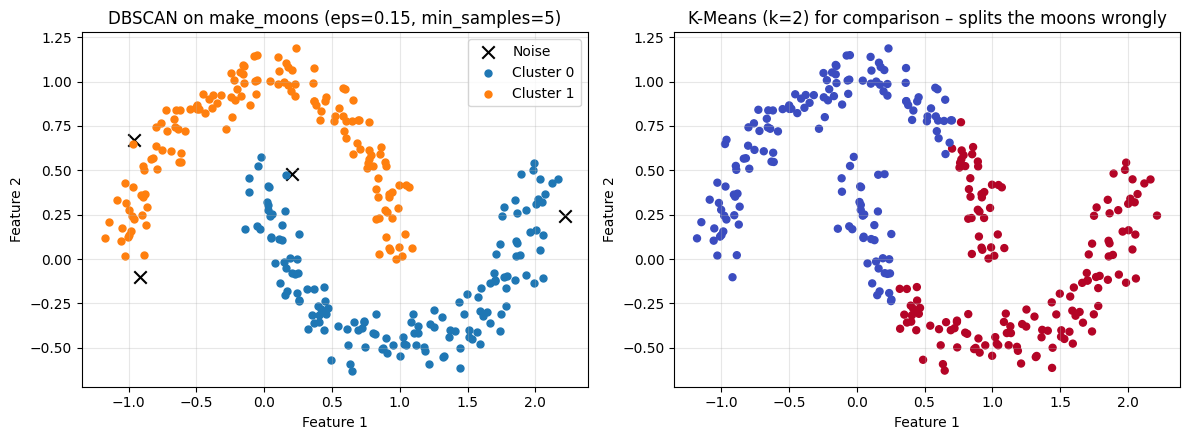

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for l in sorted(set(lab_m)):
    m = lab_m == l
    axes[0].scatter(X_moons[m, 0], X_moons[m, 1], c="black" if l == -1 else [cmap(l)],
                    marker="x" if l == -1 else "o", s=80 if l == -1 else 25, label="Noise" if l == -1 else f"Cluster {l}")
axes[0].set_title("DBSCAN on make_moons (eps=0.15, min_samples=5)"); axes[0].legend()

km_m = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_moons)
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=km_m.labels_, cmap="coolwarm", s=25)
axes[1].set_title("K-Means (k=2) for comparison – splits the moons wrongly")
for ax in axes: ax.set_xlabel("Feature 1"); ax.set_ylabel("Feature 2"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Conclusion:** DBSCAN follows the curved shape of each moon and finds the 2 true clusters, flagging the few stray points far from dense regions as noise (indices printed above). K-Means, which assumes round clusters, cuts the moons with a straight line.